# 05 · Build Your Harness

Harness가 요청을 계획하고, MCP와 Joule Agent를 호출한 뒤, 승인과 trace를 포함한 결과를 전달하는 구조입니다.


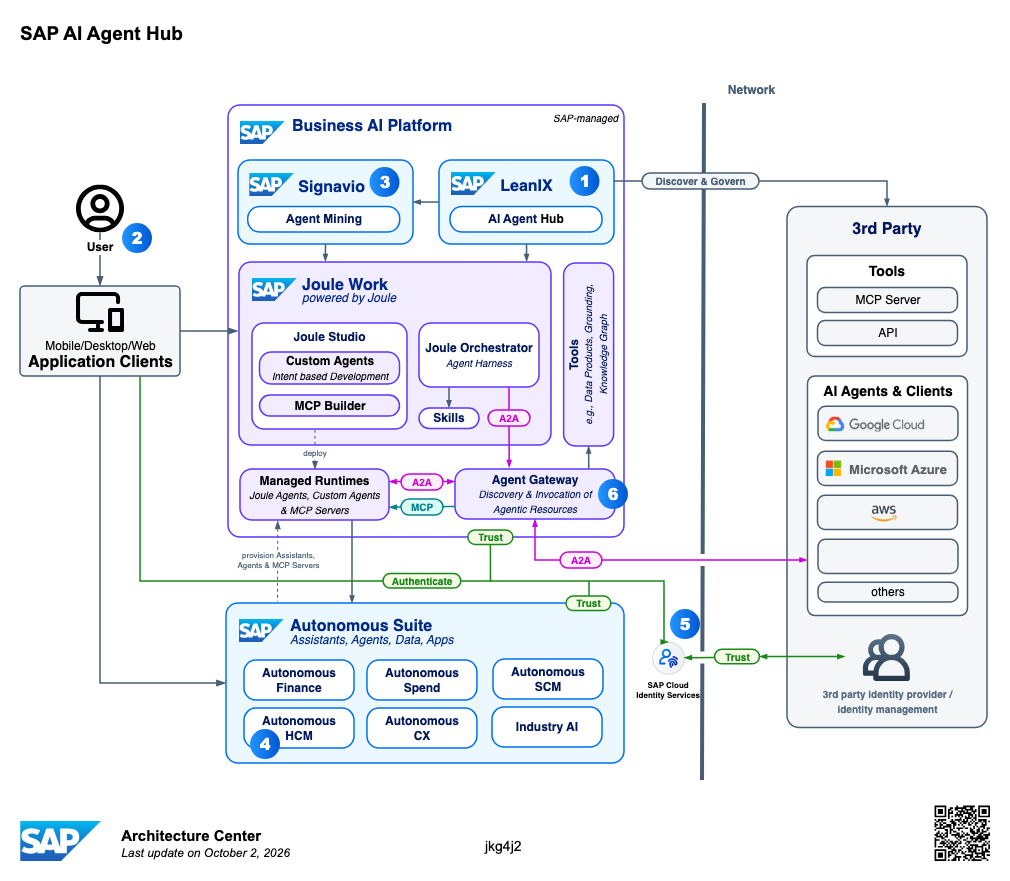

In [17]:
from IPython.display import HTML, display

display(HTML("<svg viewBox=\"0 0 1420 440\" width=\"88%\" style=\"display:block;margin:0 auto\" role=\"img\" aria-label=\"Sketch of Harness orchestrated SAP workflow\" xmlns=\"http://www.w3.org/2000/svg\">\n  <style>.paper{fill:#fcfdff;stroke:#c6d8ec;stroke-width:2;stroke-dasharray:8 5}.sketch{fill:#fff;stroke:#4f6475;stroke-width:2.4;stroke-linecap:round;stroke-linejoin:round}.focus{fill:#f8fbff;stroke:#4285f4;stroke-width:2.4;stroke-linecap:round;stroke-linejoin:round}.finish{fill:#f1faef;stroke:#34a853;stroke-width:2.4;stroke-linecap:round;stroke-linejoin:round}.ink{font:600 16px 'Comic Sans MS','Bradley Hand',cursive;fill:#263238}.note{font:14px 'Comic Sans MS','Bradley Hand',cursive;fill:#546e7a}.line{fill:none;stroke:#4f6475;stroke-width:2.2;stroke-linecap:round;marker-end:url(#arrow)}.dash{fill:none;stroke:#8b6fb0;stroke-width:2;stroke-linecap:round;stroke-dasharray:7 6}</style>\n  <defs><marker id=\"arrow\" markerWidth=\"9\" markerHeight=\"9\" refX=\"8\" refY=\"4.5\" orient=\"auto\"><path d=\"M0,0 L9,4.5 L0,9 Z\" fill=\"#4f6475\"/></marker></defs>\n  <text x=\"33\" y=\"38\" class=\"ink\" style=\"font-size:22px\">Harness-Orchestrated SAP Workflow · sketch</text>\n  <path d=\"M24 62 Q24 53 38 55 L1388 57 Q1400 58 1398 71 L1400 395 Q1399 407 1385 406 L36 408 Q23 407 24 394 Z\" class=\"paper\"/>\n  <path d=\"M45 180 Q47 170 60 172 L165 173 Q176 175 174 187 L173 244 Q170 252 159 251 L57 250 Q45 247 46 237 Z\" class=\"sketch\"/><text x=\"110\" y=\"205\" text-anchor=\"middle\" class=\"ink\">User request</text><text x=\"110\" y=\"228\" text-anchor=\"middle\" class=\"note\">purchase-order risk</text>\n  <path d=\"M240 160 Q242 151 255 153 L402 154 Q414 156 413 169 L412 261 Q409 270 398 269 L252 268 Q241 266 242 255 Z\" class=\"focus\"/><text x=\"327\" y=\"197\" text-anchor=\"middle\" class=\"ink\" style=\"fill:#0a6ed1\">Harness</text><text x=\"327\" y=\"219\" text-anchor=\"middle\" class=\"ink\" style=\"font-size:14px;fill:#0a6ed1\">Coordinator</text><text x=\"327\" y=\"244\" text-anchor=\"middle\" class=\"note\">plan · route · policy</text>\n  <path d=\"M495 75 Q497 66 510 68 L674 69 Q686 71 684 83 L683 145 Q680 154 669 153 L507 152 Q496 150 497 140 Z\" class=\"sketch\"/><text x=\"590\" y=\"104\" text-anchor=\"middle\" class=\"ink\">Integration Suite</text><text x=\"590\" y=\"128\" text-anchor=\"middle\" class=\"note\">MCP · read PO data</text>\n  <path d=\"M495 288 Q497 279 510 281 L674 282 Q686 284 684 296 L683 358 Q680 367 669 366 L507 365 Q496 363 497 353 Z\" class=\"sketch\"/><text x=\"590\" y=\"317\" text-anchor=\"middle\" class=\"ink\">Joule / Analyst</text><text x=\"590\" y=\"341\" text-anchor=\"middle\" class=\"note\">delivery-risk analysis</text>\n  <path d=\"M755 160 Q757 151 770 153 L944 154 Q956 156 954 169 L953 261 Q951 270 939 269 L767 268 Q756 266 757 255 Z\" class=\"focus\"/><text x=\"855\" y=\"199\" text-anchor=\"middle\" class=\"ink\" style=\"fill:#0a6ed1\">Synthesis + HITL</text><text x=\"855\" y=\"225\" text-anchor=\"middle\" class=\"note\">evidence · approval</text>\n  <path d=\"M1025 180 Q1027 170 1040 172 L1195 173 Q1207 175 1205 187 L1204 244 Q1201 252 1189 251 L1037 250 Q1026 247 1027 237 Z\" class=\"finish\"/><text x=\"1115\" y=\"206\" text-anchor=\"middle\" class=\"ink\" style=\"fill:#188038\">Portal result</text><text x=\"1115\" y=\"229\" text-anchor=\"middle\" class=\"note\">answer + trace</text>\n  <path d=\"M1260 160 Q1262 151 1275 153 L1380 154 Q1392 156 1390 169 L1389 261 Q1386 270 1375 269 L1272 268 Q1261 266 1262 255 Z\" class=\"finish\"/><text x=\"1326\" y=\"199\" text-anchor=\"middle\" class=\"ink\" style=\"fill:#188038\">Complete</text><text x=\"1326\" y=\"225\" text-anchor=\"middle\" class=\"note\">trace stored</text>\n  <path d=\"M174 211 L240 211 M413 211 L450 211 L450 110 L495 110 M413 211 L450 211 L450 323 L495 323 M684 110 L720 110 L720 211 L755 211 M684 323 L720 323 L720 211 M954 211 L1025 211 M1205 211 L1260 211\" class=\"line\"/>\n  <path d=\"M458 105 Q462 55 535 49\" class=\"dash\"/><text x=\"475\" y=\"66\" class=\"note\" style=\"fill:#6f42a0\">tool path</text><path d=\"M458 326 Q462 379 535 386\" class=\"dash\"/><text x=\"476\" y=\"381\" class=\"note\" style=\"fill:#6f42a0\">agent path</text>\n</svg>"))


> **실행 경계:** 조회·분석·요약은 자동화합니다. 실제 구매오더 변경은 사람 승인, 업무 권한, 별도 write workflow를 모두 통과한 뒤에만 실행합니다.

## 2. Architecture sketch


In [18]:
from IPython.display import HTML, display

display(HTML("<svg viewBox=\"0 0 1450 620\" width=\"88%\" style=\"display:block;margin:0 auto\" role=\"img\" aria-label=\"Sketch of SAP BTP Harness architecture\" xmlns=\"http://www.w3.org/2000/svg\">\n  <style>.sketch{fill:#fff;stroke:#4f6475;stroke-width:2.4;stroke-linecap:round;stroke-linejoin:round}.soft{fill:#f8fbff;stroke:#8ab4f8;stroke-width:2.2;stroke-linecap:round;stroke-linejoin:round}.hub{fill:#faf7ff;stroke:#8b6fb0;stroke-width:2.2;stroke-linecap:round;stroke-linejoin:round}.gov{fill:none;stroke:#8b6fb0;stroke-width:2;stroke-dasharray:7 6;stroke-linecap:round;marker-end:url(#govArrow)}.ink{font:600 18px 'Comic Sans MS','Bradley Hand',cursive;fill:#263238}.note{font:15px 'Comic Sans MS','Bradley Hand',cursive;fill:#546e7a}.line{fill:none;stroke:#4f6475;stroke-width:2.2;stroke-linecap:round;marker-end:url(#sketchArrow)}</style>\n  <defs><marker id=\"sketchArrow\" markerWidth=\"9\" markerHeight=\"9\" refX=\"8\" refY=\"4.5\" orient=\"auto\"><path d=\"M0,0 L9,4.5 L0,9 Z\" fill=\"#4f6475\"/></marker><marker id=\"govArrow\" markerWidth=\"9\" markerHeight=\"9\" refX=\"8\" refY=\"4.5\" orient=\"auto\"><path d=\"M0,0 L9,4.5 L0,9 Z\" fill=\"#8b6fb0\"/></marker></defs>\n  <text x=\"38\" y=\"42\" class=\"ink\" style=\"font-size:23px\">SAP BTP + Harness · sketch</text>\n  <path d=\"M55 76 Q55 67 66 68 L1132 70 Q1146 70 1144 83 L1147 520 Q1148 535 1132 534 L69 537 Q53 537 55 521 Z\" fill=\"#fcfdff\" stroke=\"#a9c7e8\" stroke-width=\"2\" stroke-dasharray=\"8 5\"/><text x=\"83\" y=\"105\" class=\"note\">SAP BTP · Cloud Foundry / Kyma</text>\n  <path d=\"M450 126 Q453 118 465 120 L727 119 Q740 121 738 133 L740 233 Q737 244 725 243 L462 244 Q449 241 450 230 Z\" class=\"soft\"/><text x=\"595\" y=\"165\" text-anchor=\"middle\" class=\"ink\" style=\"font-size:26px;fill:#0a6ed1\">Harness</text><text x=\"595\" y=\"198\" text-anchor=\"middle\" class=\"note\">Coordinator · durable workers · trace</text>\n  <path d=\"M170 334 Q171 325 184 326 L345 328 Q357 328 356 340 L354 416 Q353 427 341 426 L183 425 Q171 423 172 412 Z\" class=\"sketch\"/><text x=\"265\" y=\"365\" text-anchor=\"middle\" class=\"ink\">SAP AI Core</text><text x=\"265\" y=\"393\" text-anchor=\"middle\" class=\"note\">LLM · Reranker</text>\n  <path d=\"M425 334 Q426 325 439 326 L607 328 Q620 329 618 341 L617 416 Q616 427 603 426 L438 425 Q426 423 427 412 Z\" class=\"sketch\"/><text x=\"522\" y=\"365\" text-anchor=\"middle\" class=\"ink\">Integration Suite</text><text x=\"522\" y=\"393\" text-anchor=\"middle\" class=\"note\">MCP Gateway · API</text>\n  <path d=\"M690 334 Q691 325 704 326 L855 328 Q868 328 867 340 L865 416 Q864 427 852 426 L703 425 Q691 423 692 412 Z\" class=\"sketch\"/><text x=\"779\" y=\"365\" text-anchor=\"middle\" class=\"ink\">Joule Studio</text><text x=\"779\" y=\"393\" text-anchor=\"middle\" class=\"note\">SAP Agent · A2A</text>\n  <path d=\"M925 334 Q926 325 939 326 L1060 328 Q1073 328 1072 340 L1070 416 Q1069 427 1057 426 L938 425 Q926 423 927 412 Z\" class=\"sketch\"/><text x=\"999\" y=\"365\" text-anchor=\"middle\" class=\"ink\">HANA Cloud</text><text x=\"999\" y=\"393\" text-anchor=\"middle\" class=\"note\">state · memory</text>\n  <path d=\"M530 245 L270 326 M565 245 L522 326 M630 245 L779 326 M675 245 L999 326\" class=\"line\"/><path d=\"M522 426 L522 480 L673 480\" class=\"line\"/><text x=\"690\" y=\"486\" class=\"note\">S/4HANA · SuccessFactors · Ariba · External APIs</text>\n  <path d=\"M740 180 C900 130 1080 150 1215 275\" class=\"gov\"/><path d=\"M1218 240 Q1220 232 1232 234 L1405 235 Q1417 236 1415 248 L1414 365 Q1412 376 1400 375 L1230 374 Q1218 372 1219 361 Z\" class=\"hub\"/><text x=\"1315\" y=\"278\" text-anchor=\"middle\" class=\"ink\" style=\"font-size:20px;fill:#6f42a0\">LeanIX</text><text x=\"1315\" y=\"306\" text-anchor=\"middle\" class=\"ink\" style=\"font-size:16px;fill:#6f42a0\">AI Agent Hub</text><text x=\"1315\" y=\"334\" text-anchor=\"middle\" class=\"note\" style=\"fill:#6f42a0\">Agent Card · registry</text><text x=\"1315\" y=\"356\" text-anchor=\"middle\" class=\"note\" style=\"fill:#6f42a0\">approval · governance</text><text x=\"1100\" y=\"173\" text-anchor=\"middle\" class=\"note\" style=\"fill:#6f42a0\">approval status sync</text>\n</svg>"))


## 3. SAP 제품별 역할과 구현 경계

| 제품 / 계층 | Harness에서 맡기는 일 | 구현 시 확인할 계약 |
| --- | --- | --- |
| SAP AI Core | LLM, reranker, 모델 추론 | 배포 모델, prompt/input schema, token·rate limit |
| SAP Integration Suite | MCP Gateway와 기업 API 연결 | Tool schema, OAuth, 읽기·쓰기 권한, audit |
| Joule Studio / Agents | SAP 업무 Agent를 A2A로 제공 | Agent Card, endpoint, 인증, task·artifact schema |
| SAP HANA Cloud | 상태, memory, checkpoint, trace 저장 | 업무 키, 보존 기간, PII 분류 |
| LeanIX AI Agent Hub | Agent 등록, 검색, 승인, EA 관계 | registry ID, 승인 상태, 동기화 주기 |
| SAP S/4HANA | 구매오더 등 실제 ERP 데이터·트랜잭션 | API scope, 업무 권한, idempotency key |

### MCP는 어떤 SAP 제품을 쓰나?

이 구조에서 MCP의 중심은 **SAP Integration Suite**입니다. Harness의 MCP adapter가 Integration Suite의 MCP Gateway / API integration layer를 통해 S/4HANA, SuccessFactors, Ariba 같은 기업 API를 Tool로 호출합니다. 실제 제공 기능, endpoint, 인증 방식은 사용하는 BTP tenant와 제품 설정에서 확인해야 합니다.

### Agent Hub는 실행이 아니라 거버넌스

Agent Hub를 매 요청마다 호출하지 않습니다. Agent 생성·수정 때 Harness Agent Card를 등록하고, 검색과 승인 상태 동기화에 사용합니다. 실제 실행은 Harness가 검증된 MCP와 Joule runtime을 직접 호출합니다.


## 4. 업무 요청 처리 순서

예시: “구매오더 상태를 확인하고 납품 지연 위험을 분석해 줘.”


In [19]:
from IPython.display import HTML, display

display(HTML("<svg viewBox=\"0 0 1200 300\" width=\"88%\" style=\"display:block;margin:0 auto\" role=\"img\" aria-label=\"Sketch of business request processing sequence\" xmlns=\"http://www.w3.org/2000/svg\">\n  <style>.paper{fill:#fcfdff;stroke:#c6d8ec;stroke-width:2;stroke-dasharray:8 5}.bubble{fill:#fff;stroke:#4f6475;stroke-width:2.3;stroke-linecap:round;stroke-linejoin:round}.focus{fill:#f8fbff;stroke:#4285f4;stroke-width:2.3;stroke-linecap:round;stroke-linejoin:round}.review{fill:#fffaf0;stroke:#d99000;stroke-width:2.3;stroke-linecap:round;stroke-linejoin:round}.ink{font:600 16px 'Comic Sans MS','Bradley Hand',cursive;fill:#263238}.note{font:14px 'Comic Sans MS','Bradley Hand',cursive;fill:#546e7a}.line{fill:none;stroke:#4f6475;stroke-width:2.2;stroke-linecap:round;marker-end:url(#arrow)}.dash{fill:none;stroke:#8b6fb0;stroke-width:2;stroke-dasharray:7 6;stroke-linecap:round}</style>\n  <defs><marker id=\"arrow\" markerWidth=\"9\" markerHeight=\"9\" refX=\"8\" refY=\"4.5\" orient=\"auto\"><path d=\"M0,0 L9,4.5 L0,9 Z\" fill=\"#4f6475\"/></marker></defs>\n  <text x=\"30\" y=\"37\" class=\"ink\" style=\"font-size:21px\">구매오더 납품 지연 위험 · 업무 처리 순서</text>\n  <path d=\"M22 58 Q22 49 36 51 L1165 52 Q1178 53 1177 66 L1179 263 Q1178 276 1165 275 L35 277 Q22 276 22 263 Z\" class=\"paper\"/>\n  <path d=\"M52 137 Q54 126 67 128 L163 129 Q176 131 174 143 L173 201 Q171 211 159 210 L65 209 Q53 207 54 196 Z\" class=\"bubble\"/><text x=\"113\" y=\"159\" text-anchor=\"middle\" class=\"ink\">1. 요청</text><text x=\"113\" y=\"183\" text-anchor=\"middle\" class=\"note\">PO 위험 확인</text>\n  <path d=\"M268 137 Q270 126 283 128 L397 129 Q410 131 408 143 L407 201 Q405 211 393 210 L281 209 Q269 207 270 196 Z\" class=\"focus\"/><text x=\"339\" y=\"159\" text-anchor=\"middle\" class=\"ink\" style=\"fill:#0a6ed1\">2. Harness</text><text x=\"339\" y=\"183\" text-anchor=\"middle\" class=\"note\">계획 · 라우팅</text>\n  <path d=\"M500 137 Q502 126 515 128 L649 129 Q662 131 660 143 L659 201 Q657 211 645 210 L513 209 Q501 207 502 196 Z\" class=\"bubble\"/><text x=\"581\" y=\"159\" text-anchor=\"middle\" class=\"ink\">3. Integration MCP</text><text x=\"581\" y=\"183\" text-anchor=\"middle\" class=\"note\">S/4HANA 읽기 조회</text>\n  <path d=\"M752 137 Q754 126 767 128 L885 129 Q898 131 896 143 L895 201 Q893 211 881 210 L765 209 Q753 207 754 196 Z\" class=\"focus\"/><text x=\"825\" y=\"159\" text-anchor=\"middle\" class=\"ink\" style=\"fill:#0a6ed1\">4. Joule / Analyst</text><text x=\"825\" y=\"183\" text-anchor=\"middle\" class=\"note\">지연 위험 분석</text>\n  <path d=\"M988 137 Q990 126 1003 128 L1130 129 Q1143 131 1141 143 L1140 201 Q1138 211 1126 210 L1001 209 Q989 207 990 196 Z\" class=\"review\"/><text x=\"1066\" y=\"159\" text-anchor=\"middle\" class=\"ink\" style=\"fill:#9a6700\">5. HITL + Portal</text><text x=\"1066\" y=\"183\" text-anchor=\"middle\" class=\"note\">승인 · 결과 · trace</text>\n  <path d=\"M174 169 L268 169 M408 169 L500 169 M660 169 L752 169 M896 169 L988 169\" class=\"line\"/>\n  <path d=\"M1012 122 Q1050 86 1115 105\" class=\"dash\"/><text x=\"1065\" y=\"91\" text-anchor=\"middle\" class=\"note\" style=\"fill:#6f42a0\">고위험 · 실제 변경이면 승인</text>\n  <text x=\"600\" y=\"245\" text-anchor=\"middle\" class=\"note\">조회와 분석은 자동화 · 결과와 근거는 trace로 보존</text>\n</svg>"))
